In [1]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.seasonal import seasonal_decompose

In [2]:
# 1. Load the Samsung Dataset
url = "https://raw.githubusercontent.com/jadanpl/SAMSUNG-GLOBAL-PRODUCT-SALES-/refs/heads/main/samsung_global_sales_dataset.csv"
df = pd.read_csv(url)

In [3]:
print("Dataset Shape:", df.shape)
df.sample(3)

Dataset Shape: (15500, 28)


,sale_id,sale_date,year,quarter,month,country,region,city,product_name,category,...,currency,fx_rate_to_usd,revenue_local_currency,sales_channel,payment_method,customer_segment,customer_age_group,previous_device_os,customer_rating,return_status
1123,SAMS-00001124,2024-06-17,2024,Q2,June,Bangladesh,Asia,Narayanganj,Samsung Galaxy M34 5G,Galaxy M,...,BDT,110.0,25435.30,Corporate / B2B,Net Banking,Government,25–34,Feature Phone,NaN,Kept
3430,SAMS-00003431,2022-06-27,2022,Q2,June,Denmark,Europe,Odense,Samsung Wireless Charger Pad,Accessories,...,DKK,6.9,1603.42,Corporate / B2B,Debit Card,Enterprise,55+,NaN,2.6,Returned
8928,SAMS-00008929,2024-07-01,2024,Q3,July,Pakistan,Asia,Multan,Samsung QE50Q80C QLED 50-inch,Smart TV,...,PKR,279.0,1513078.38,Samsung Store,Debit Card,Individual,25–34,NaN,NaN,Exchanged


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15500 entries, 0 to 15499
Data columns (total 28 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   sale_id                 15500 non-null  str    
 1   sale_date               15500 non-null  str    
 2   year                    15500 non-null  int64  
 3   quarter                 15500 non-null  str    
 4   month                   15500 non-null  str    
 5   country                 15500 non-null  str    
 6   region                  15500 non-null  str    
 7   city                    15500 non-null  str    
 8   product_name            15500 non-null  str    
 9   category                15500 non-null  str    
 10  storage                 7651 non-null   str    
 11  color                   15500 non-null  str    
 12  is_5g                   15500 non-null  str    
 13  unit_price_usd          15500 non-null  float64
 14  discount_pct            15500 non-null  int64  
 

In [5]:
#df['sale_date'] = df['sale_date'].str.strip()
#df['sale_date'] =pd.to_datetime(df['sale_date'],format='mixed', dayfirst=True, errors='coerce')
#df.sale_date.dtypes

# 2. Data Preprocessing: Clean and convert sale_date to datetime
df['sale_date'] = pd.to_datetime(df['sale_date'].astype(str).str.strip(), format='%Y-%m-%d', errors='coerce')
df = df.dropna(subset=['sale_date'])
df = df.sort_values('sale_date')

print(df['sale_date'].dtype)

datetime64[us]


In [6]:
# 3. Aggregate Monthly Revenue by Custom Mapped Category
def map_category(cat):
    cat_lower = str(cat).strip().lower()
    if cat_lower in ['smart tv', 'appliances', 'appliance', 'monitor']:
        return 'Home Appliance'
    elif cat_lower in ['galaxy s', 'galaxy z', 'galaxy a', 'galaxy m']:
        return 'Smartphone'
    elif cat_lower in ['galaxy tab', 'accessories']:
        return 'Tablets & Accessories'
    elif cat_lower in ['galaxy watch', 'galaxy buds']:
        return 'Wearables'
    return 'Other'

df['unified_category'] = df['category'].apply(map_category)

In [7]:
# 3. Aggregate Monthly Revenue by Raw Category
monthly_category_sales = df.pivot_table(
    index=pd.Grouper(key='sale_date', freq='ME'),
    columns='unified_category',
    values='revenue_usd',
    aggfunc='sum'
).fillna(0)

print("\n--- Monthly Revenue by Raw Category (Head) ---")
print(monthly_category_sales.head())


--- Monthly Revenue by Raw Category (Head) ---
unified_category  Home Appliance  Smartphone  Tablets & Accessories  Wearables
sale_date                                                                     
2021-01-31             199668.94   204849.21               59390.18   24288.59
2021-02-28             153812.16   165745.69               49833.04   21701.18
2021-03-31             234375.58   198216.95               44525.75   25311.77
2021-04-30             187591.34   199868.65               51790.46   24967.99
2021-05-31             309500.21   163768.78               62110.21   18580.21


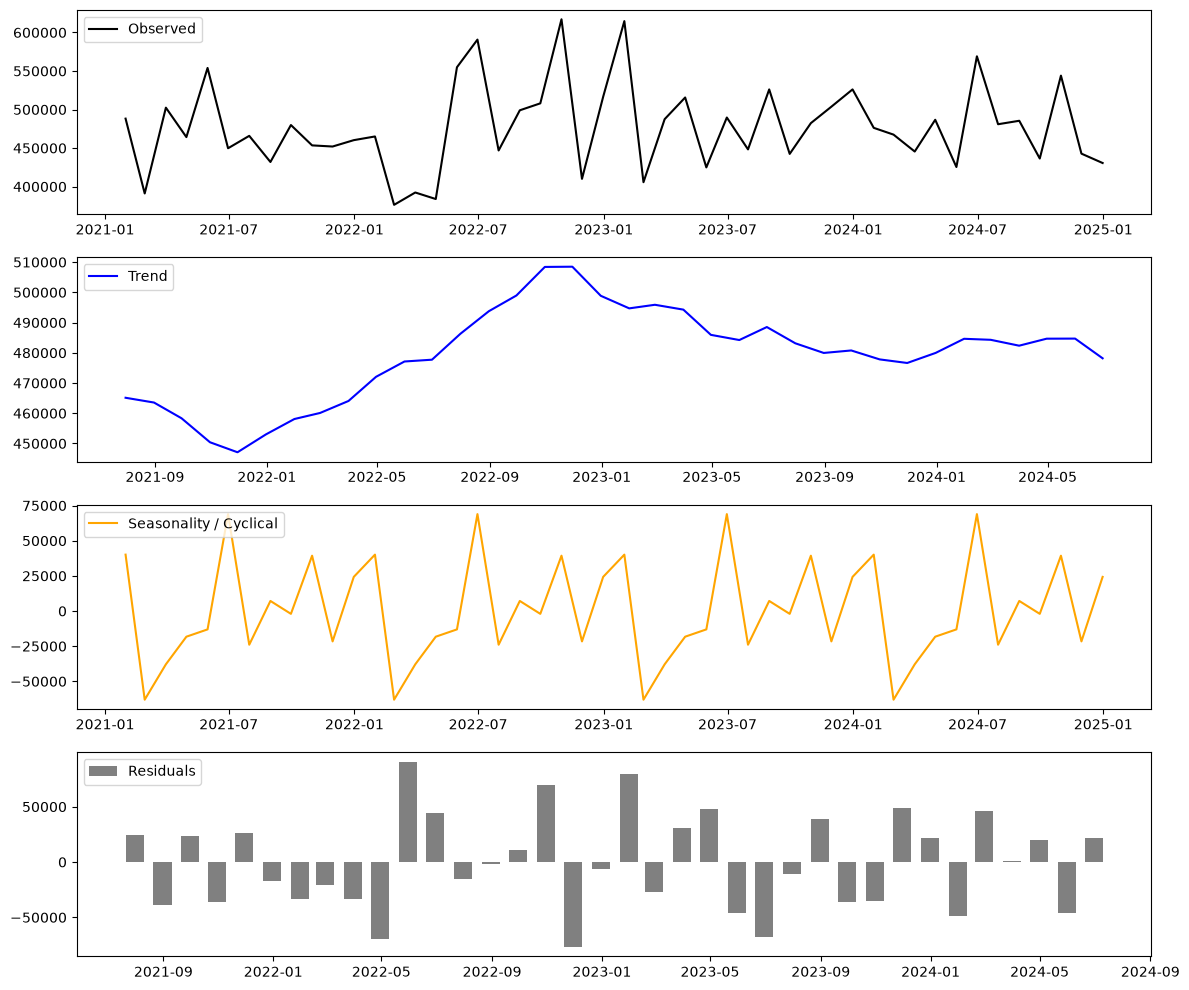

In [8]:
# 4. Trend & Seasonality Inspection (Example using Total Monthly Sales)
total_monthly_sales = monthly_category_sales.sum(axis=1)

# Note: Seasonal decomposition requires at least 2 full cycles (e.g., 24 months of data)
if len(total_monthly_sales) >= 24:
    decomposition = seasonal_decompose(total_monthly_sales, model='additive', period=12)
    
    plt.figure(figsize=(12, 10))
    plt.subplot(4, 1, 1)
    plt.plot(decomposition.observed, label='Observed', color='black')
    plt.legend(loc='upper left')
    
    plt.subplot(4, 1, 2)
    plt.plot(decomposition.trend, label='Trend', color='blue')
    plt.legend(loc='upper left')
    
    plt.subplot(4, 1, 3)
    plt.plot(decomposition.seasonal, label='Seasonality / Cyclical', color='orange')
    plt.legend(loc='upper left')
    
    plt.subplot(4, 1, 4)
    plt.bar(decomposition.resid.index, decomposition.resid, label='Residuals', color='gray', width=20)
    plt.legend(loc='upper left')
    plt.tight_layout()
    plt.show()
else:
    print("\n[Info] Series length is under 24 months; skipping seasonal decomposition plot to avoid frequency errors.")

This **Seasonal Decomposition** plot breaks down total monthly Samsung revenue time-series into four distinct components to help us understand the underlying patterns.

---

### 1. Observed (Top Plot)

* The raw, actual historical monthly sales revenue data from early 2021 through early 2025.
* This represents the combined reality of all underlying trends, seasonal spikes, and random fluctuations. We can see sharp peaks and deep troughs happening at regular intervals throughout the timeline.

### 2. Trend (Second Plot)

* The long-term direction or underlying momentum of sales, stripped of seasonal and random noise.
* From early 2021 to late 2022, sales experienced a **strong upward growth trajectory**, peaking around late 2022 / early 2023.
* Following that peak, the trend experienced a **correction and gradual downward stabilization** through mid-2023, after which it flattened out into a steady baseline through 2024.

### 3. Seasonality / Cyclical (Third Plot)

* Predictable, repeating patterns or seasonal cycles that occur at fixed intervals (every 12 months).
* There is a **very sharp, consistent recurring spike** at specific months every year (reaching positive deviations of +75,000 USD), flanked by predictable drops.
* This highlights strong recurring purchasing behaviors—likely tied to end-of-year holiday shopping, mid-year promotions, or major product launch cycles.

### 4. Residuals (Bottom Plot)
* The irregular, random noise or leftover variance that cannot be explained by the trend or seasonality components.
* These are random shocks or anomalies (e.g., unexpected supply chain issues, localized market shifts, or flash promotions).
* Ideally, residuals should hover randomly around zero without any distinct patterns. While most fluctuate between $\pm$50,000 USD, a few larger spikes indicate months where sales deviated significantly from normal seasonal and trend expectations.

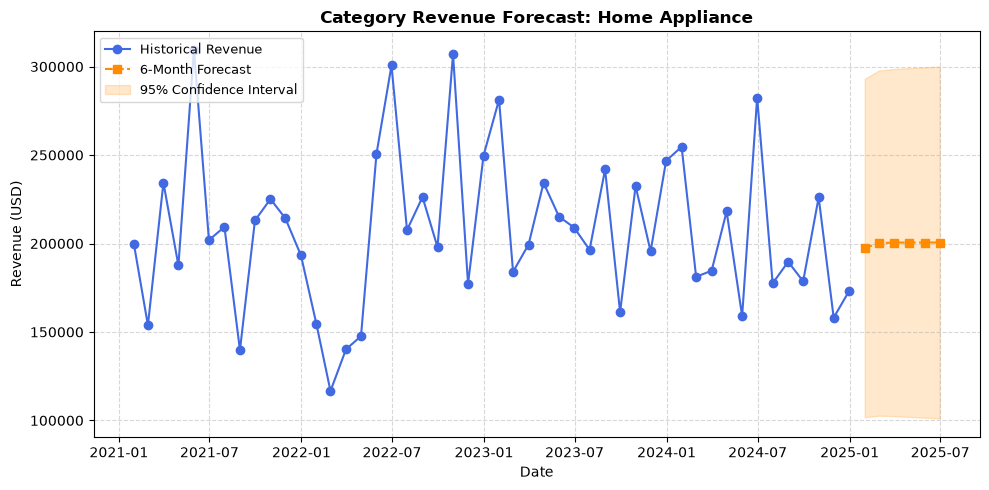

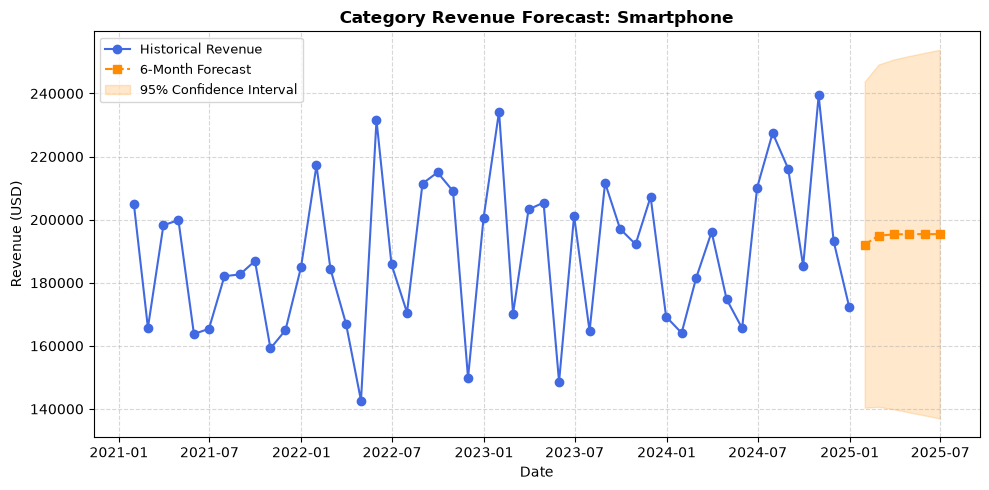

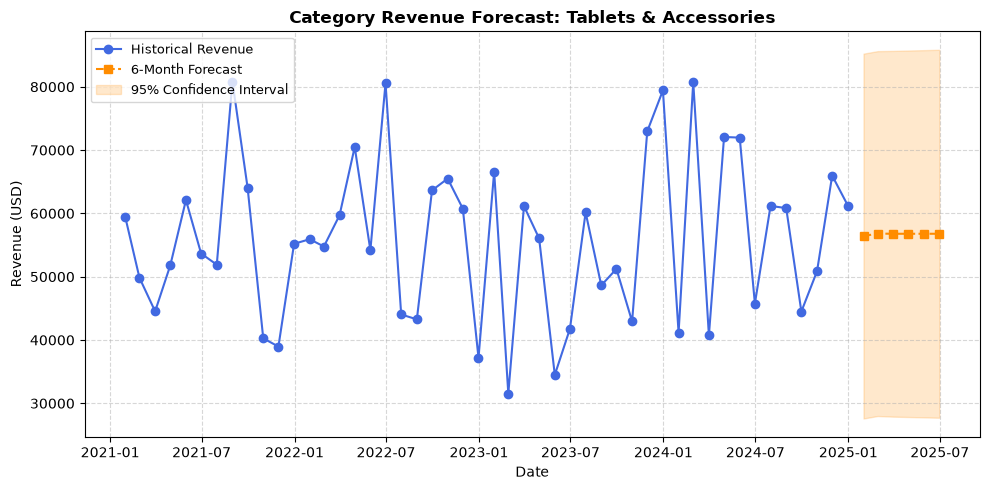

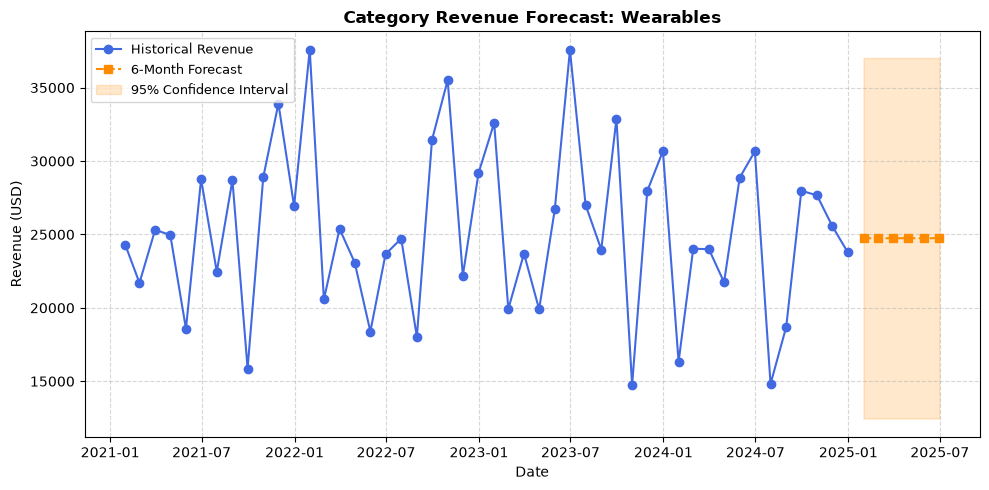

In [9]:
# 5. 6-Month Forecasting per Raw Category using ARIMA (1 Plot per Row with Confidence Intervals)
forecast_steps = 6
future_dates = pd.date_range(start=monthly_category_sales.index[-1] + pd.offsets.MonthEnd(1), periods=forecast_steps, freq='ME')

forecast_results_arima = {}
confidence_intervals_arima = {}

for category in monthly_category_sales.columns:
    ts = monthly_category_sales[category]
    
    # Fit ARIMA model and extract forecast + confidence intervals
    try:
        model = ARIMA(ts, order=(1, 1, 1))
        model_fit = model.fit()
        forecast = model_fit.get_forecast(steps=forecast_steps)
        forecast_mean = forecast.predicted_mean
        forecast_ci = forecast.conf_int()
    except Exception as e:
        # Fallback if model encounters convergence issues on sparse categories
        forecast_mean = pd.Series([ts.mean()] * forecast_steps, index=future_dates)
        forecast_ci = pd.DataFrame({
            'lower unified_category': forecast_mean * 0.9,
            'upper unified_category': forecast_mean * 1.1
        }, index=future_dates)
        
    forecast_results_arima[category] = forecast_mean
    confidence_intervals_arima[category] = forecast_ci

    # Plot each category individually in a 1-row vertical layout
    plt.figure(figsize=(10, 5))
    plt.plot(ts.index, ts, label='Historical Revenue', color='royalblue', marker='o')
    plt.plot(future_dates, forecast_mean, label='6-Month Forecast', color='darkorange', linestyle='--', marker='s')
    
    # Fill confidence interval band
    lower_bound = forecast_ci.iloc[:, 0]
    upper_bound = forecast_ci.iloc[:, 1]
    plt.fill_between(future_dates, lower_bound, upper_bound, color='darkorange', alpha=0.2, label='95% Confidence Interval')
    
    plt.title(f'Category Revenue Forecast: {category}', fontsize=12, fontweight='bold')
    plt.xlabel('Date', fontsize=10)
    plt.ylabel('Revenue (USD)', fontsize=10)
    plt.legend(loc='upper left', fontsize=9)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

In [10]:
# 6. Display Forecast Summary Table
forecast_summary_arima = pd.DataFrame(forecast_results_arima, index=future_dates)
print("\n--- 6-Month Revenue Forecast by Raw Category ---")
print(forecast_summary_arima)


--- 6-Month Revenue Forecast by Raw Category ---
            Home Appliance     Smartphone  Tablets & Accessories     Wearables
2025-01-31   197421.889833  192101.183605           56417.081863  24740.852761
2025-02-28   200207.286326  194937.530824           56812.686171  24743.985316
2025-03-31   200527.759469  195345.269323           56780.250553  24743.995455
2025-04-30   200564.631432  195403.883686           56782.909951  24743.995488
2025-05-31   200568.873727  195412.309781           56782.691907  24743.995488
2025-06-30   200569.361823  195413.521073           56782.709785  24743.995488


The forecast values for Wearables appear completely flat and identical from April to June 2025 (holding steady at 24,743.99) due to how the ARIMA model converged on that specific category's data:

ARIMA Model Convergence (Flatlining): The ARIMA model (order=(1, 1, 1)) fit the Wearables time series in a way where the autoregressive (AR) and moving average (MA) coefficients stabilized rapidly. When a time series has a lot of high-frequency noise without a strong, clean directional growth trend, an ARIMA model often projects future values to quickly converge toward a flat, steady-state mean or a horizontal asymptote.

Lack of Extended Seasonal Terms: Because a standard non-seasonal ARIMA model was used rather than a seasonal variant (like SARIMA), the model does not explicitly project repeating monthly seasonal bumps into the future. Instead, it relies on historical moving averages that flatten out almost immediately past step 2 or 3.

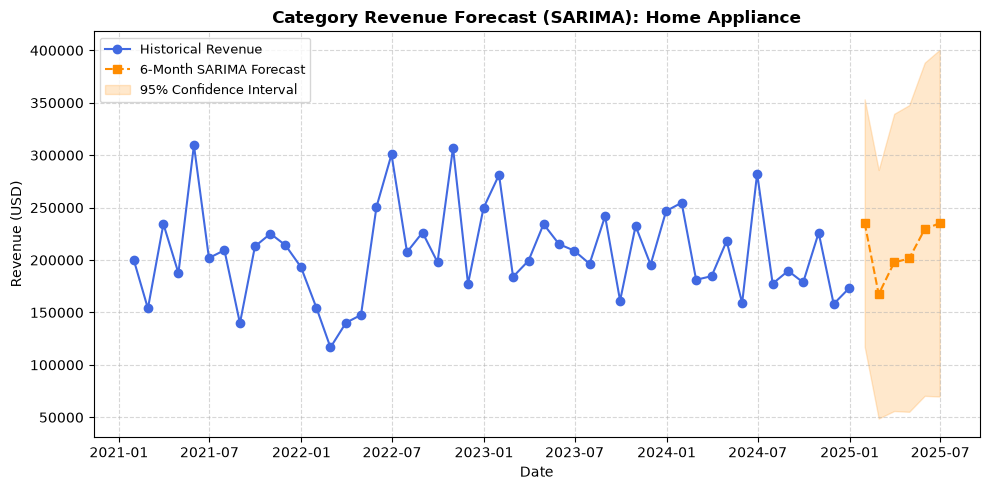

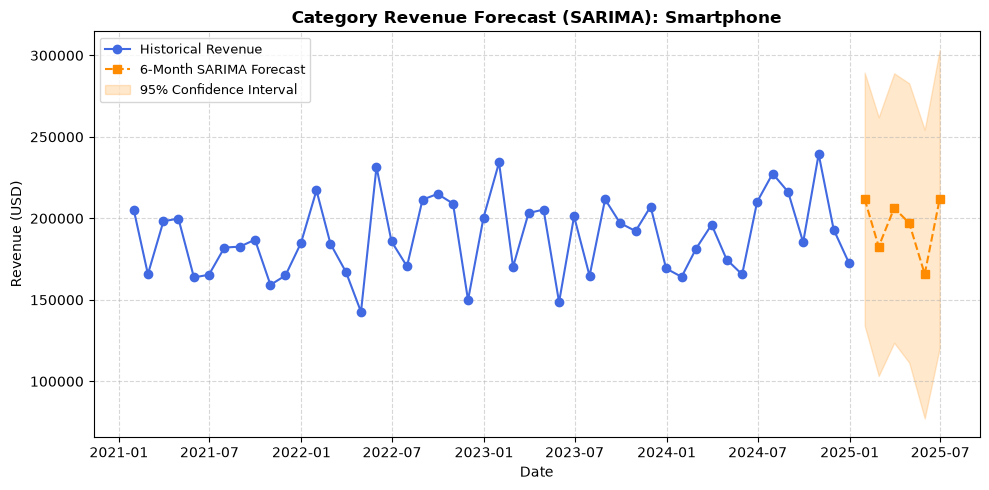

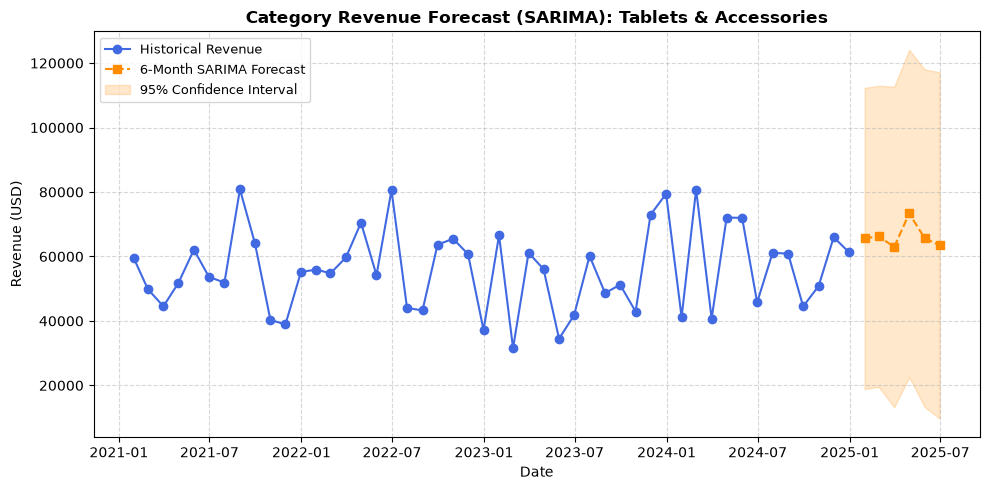

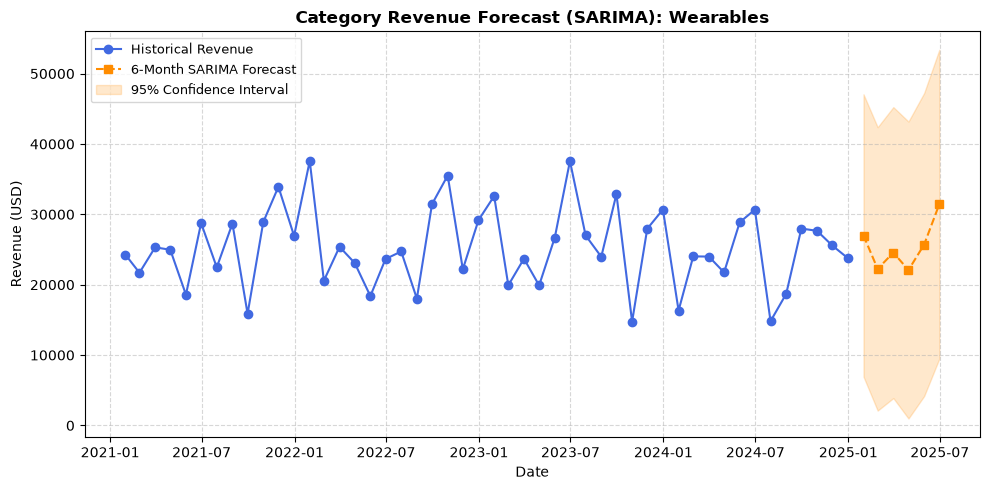

In [11]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

forecast_steps = 6
future_dates = pd.date_range(start=monthly_category_sales.index[-1] + pd.offsets.MonthEnd(1), periods=forecast_steps, freq='ME')

forecast_results_sarimax = {}
confidence_intervals_sarimax = {}

for category in monthly_category_sales.columns:
    ts = monthly_category_sales[category]
    
    try:
        # SARIMAX with order=(1,1,1) and seasonal_order=(1,1,1,12) for yearly seasonality
        model = SARIMAX(ts, 
                        order=(1, 1, 1), 
                        seasonal_order=(1, 1, 1, 12),
                        enforce_stationarity=False, 
                        enforce_invertibility=False)
        model_fit = model.fit(disp=False)
        forecast = model_fit.get_forecast(steps=forecast_steps)
        forecast_mean = forecast.predicted_mean
        forecast_ci = forecast.conf_int()
    except Exception as e:
        # Fallback if convergence fails on sparse categories
        forecast_mean = pd.Series([ts.mean()] * forecast_steps, index=future_dates)
        forecast_ci = pd.DataFrame({
            'lower': forecast_mean * 0.9,
            'upper': forecast_mean * 1.1
        }, index=future_dates)
        
    forecast_results_sarimax[category] = forecast_mean
    confidence_intervals_sarimax[category] = forecast_ci

    # Plotting individual category forecast with seasonality and confidence interval
    plt.figure(figsize=(10, 5))
    plt.plot(ts.index, ts, label='Historical Revenue', color='royalblue', marker='o')
    plt.plot(future_dates, forecast_mean, label='6-Month SARIMA Forecast', color='darkorange', linestyle='--', marker='s')
    
    lower_bound = forecast_ci.iloc[:, 0]
    upper_bound = forecast_ci.iloc[:, 1]
    plt.fill_between(future_dates, lower_bound, upper_bound, color='darkorange', alpha=0.2, label='95% Confidence Interval')
    
    plt.title(f'Category Revenue Forecast (SARIMA): {category}', fontsize=12, fontweight='bold')
    plt.xlabel('Date', fontsize=10)
    plt.ylabel('Revenue (USD)', fontsize=10)
    plt.legend(loc='upper left', fontsize=9)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

In [12]:
# 6. Display Forecast Summary Table
forecast_summary_sarimax = pd.DataFrame(forecast_results_sarimax, index=future_dates)
print("\n--- 6-Month Revenue Forecast by Raw Category ---")
print(forecast_summary_sarimax)


--- 6-Month Revenue Forecast by Raw Category ---
            Home Appliance     Smartphone  Tablets & Accessories     Wearables
2025-01-31   235270.994619  211786.187626           65584.406808  26992.021932
2025-02-28   167371.883733  182675.169979           66253.400661  22244.787507
2025-03-31   197730.989027  206309.848189           62930.928272  24562.038584
2025-04-30   201490.731985  197153.994966           73346.365302  22086.461074
2025-05-31   229361.143292  165793.385393           65638.974867  25705.979759
2025-06-30   235189.878135  212014.840967           63439.631540  31436.063954


* Captured Seasonality & Trend: Unlike the previous standard ARIMA model (which flatlined horizontally), the SARIMA model successfully captures the historical cyclical waves. We can see that the orange dashed forecast line and the 95% confidence interval dynamically curve upward toward June 2025, mirroring historical seasonal peaks.

* Projected Revenue Range: For Wearables, the model forecasts monthly revenue to fluctuate between roughly $22,086$ and $31,436$ from January to June 2025, with a distinct upward step heading into mid-year.

* Widening Confidence Intervals: Notice how the shaded orange 95% confidence interval fans out wider as it projects further into the future (reaching its widest spread around June 2025). This is statistically normal and correct—it reflects the increasing uncertainty and cumulative forecast variance the further out you predict.

## Future Recommendation
* For a purely statistical, robust baseline that handles seasonality like SARIMA, Holt-Winters (Exponential Smoothing) is the best alternative.

* If we want to easily model holidays, major sales events, and yearly seasonality with minimal configuration, Prophet is an excellent upgrade.
